In [6]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from src.features import make_features

df_clean = pd.read_parquet("../data/processed/electricity_clean.parquet")
temp = pd.read_parquet("../data/processed/air_temperature.parquet")
train_buildings = pd.read_csv("../configs/train_buildings.csv")["building"].tolist()

rng = np.random.default_rng(0)
sample = rng.choice(train_buildings, size=100, replace=False)
data = pd.concat([make_features(b, df_clean, temp) for b in sample])

FEATS = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
year, month = data.index.year, data.index.month
fit = data[(year == 2016) & (month <= 10)].dropna(subset=["load_n"])
cal = data[(year == 2016) & (month >= 11)].dropna(subset=["load_n"])
test = data[year == 2017].dropna(subset=["load_n"])
print(len(fit), "fit rows,", len(cal), "calibration rows,", len(test), "test rows")

702198 fit rows, 143356 calibration rows, 864321 test rows


In [7]:
y = test["load"].to_numpy()
scale = test["scale"].to_numpy()

def report(name, lo, hi):
    covered = (y >= lo) & (y <= hi)
    width = (hi - lo) / scale
    print(f"{name}: coverage {covered.mean():.3f}, mean relative width {width.mean():.3f}")

q_models = {}
for q in [0.05, 0.95]:
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0)
    m.fit(fit[FEATS], fit["load_n"])
    q_models[q] = m

lo_a = q_models[0.05].predict(test[FEATS]) * scale
hi_a = q_models[0.95].predict(test[FEATS]) * scale
report("Quantile GBM", lo_a, hi_a)


Quantile GBM: coverage 0.891, mean relative width 0.446


In [8]:
point = HistGradientBoostingRegressor(random_state=0)
point.fit(fit[FEATS], fit["load_n"])

res_cal = np.abs(cal["load_n"].to_numpy() - point.predict(cal[FEATS]))
alpha = 0.1
n = len(res_cal)
level = np.ceil((n + 1) * (1 - alpha)) / n
q_hat = np.quantile(res_cal, level, method="higher")
print("q_hat =", round(q_hat, 3))

pred = point.predict(test[FEATS])
lo_b = (pred - q_hat) * scale
hi_b = (pred + q_hat) * scale
report("Split conformal", lo_b, hi_b)

q_hat = 0.255
Split conformal: coverage 0.895, mean relative width 0.511


In [9]:
y_cal = cal["load_n"].to_numpy()
lo_cal = q_models[0.05].predict(cal[FEATS])
hi_cal = q_models[0.95].predict(cal[FEATS])
scores = np.maximum(lo_cal - y_cal, y_cal - hi_cal)

n = len(scores)
level = np.ceil((n + 1) * (1 - alpha)) / n
q_cqr = np.quantile(scores, level, method="higher")
print("q_cqr =", round(q_cqr, 3))

lo_c = (q_models[0.05].predict(test[FEATS]) - q_cqr) * scale
hi_c = (q_models[0.95].predict(test[FEATS]) + q_cqr) * scale
report("CQR", lo_c, hi_c)

q_cqr = -0.001
CQR: coverage 0.890, mean relative width 0.444


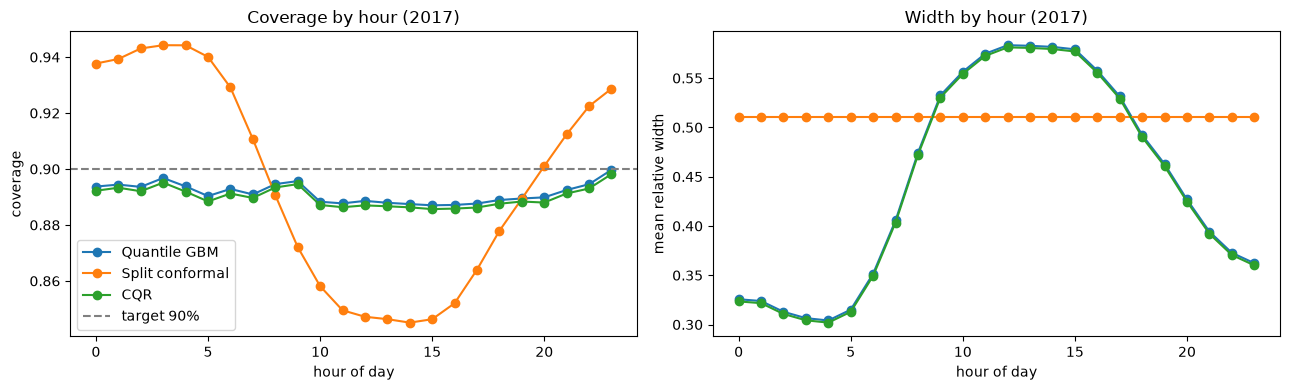

In [15]:
import matplotlib.pyplot as plt

hours = test["hour"].to_numpy()
methods = {"Quantile GBM": (lo_a, hi_a),
           "Split conformal": (lo_b, hi_b),
           "CQR": (lo_c, hi_c)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (lo, hi) in methods.items():
    covered = pd.Series((y >= lo) & (y <= hi))
    width = pd.Series((hi - lo) / scale)
    axes[0].plot(covered.groupby(hours).mean(), marker="o", label=name)
    axes[1].plot(width.groupby(hours).mean(), marker="o", label=name)
axes[0].axhline(0.9, color="gray", ls="--", label="target 90%")
axes[0].set(xlabel="hour of day", ylabel="coverage", title="Coverage by hour (2017)")
axes[1].set(xlabel="hour of day", ylabel="mean relative width", title="Width by hour (2017)")
axes[0].legend()
fig.tight_layout()

Quantile GBM: 16 of 100 buildings below 80% coverage, lowest 0.66 (Gator_public_Natasha)
Split conformal: 13 of 100 buildings below 80% coverage, lowest 0.46 (Wolf_education_Cody)
CQR: 16 of 100 buildings below 80% coverage, lowest 0.66 (Gator_public_Natasha)


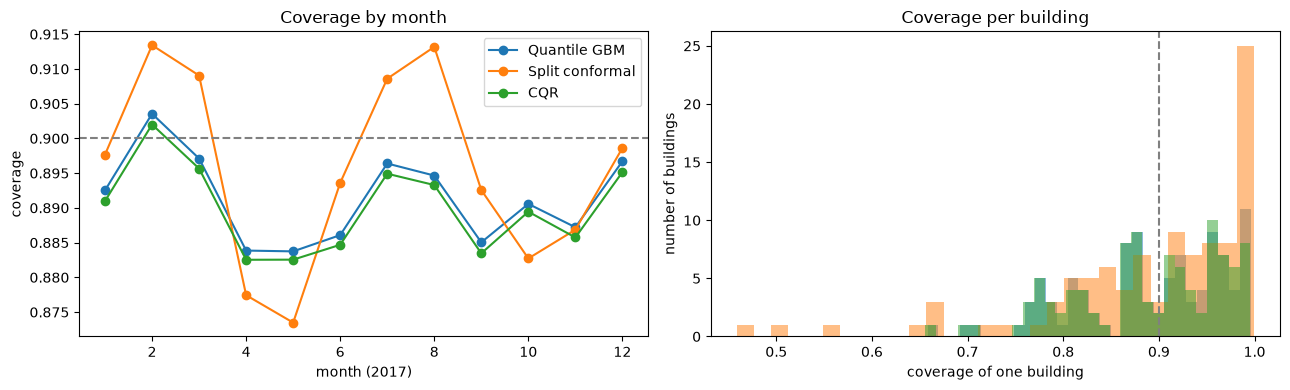

In [16]:
months = test.index.month.to_numpy()
buildings = test["building"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (lo, hi) in methods.items():
    covered = pd.Series((y >= lo) & (y <= hi))
    axes[0].plot(covered.groupby(months).mean(), marker="o", label=name)
    per_b = covered.groupby(buildings).mean()
    axes[1].hist(per_b, bins=30, alpha=0.5, label=name)
    print(f"{name}: {(per_b < 0.8).sum()} of {len(per_b)} buildings below 80% coverage, "
          f"lowest {per_b.min():.2f} ({per_b.idxmin()})")
axes[0].axhline(0.9, color="gray", ls="--")
axes[0].set(xlabel="month (2017)", ylabel="coverage", title="Coverage by month")
axes[1].axvline(0.9, color="gray", ls="--")
axes[1].set(xlabel="coverage of one building", ylabel="number of buildings",
            title="Coverage per building")
axes[0].legend()
fig.tight_layout()

In [12]:
def conformal_q(r):
    n = len(r)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(r, level, method="higher")

def per_building_q(cal_scores, test_buildings):
    q_by_b = pd.Series(cal_scores).groupby(cal["building"].to_numpy()).apply(
        lambda r: conformal_q(r.to_numpy()))
    return pd.Series(test_buildings).map(q_by_b).to_numpy()

test_b = test["building"].to_numpy()

q_split_b = per_building_q(res_cal, test_b)
lo_d = (pred - q_split_b) * scale
hi_d = (pred + q_split_b) * scale

q_cqr_b = per_building_q(scores, test_b)
lo_e = (q_models[0.05].predict(test[FEATS]) - q_cqr_b) * scale
hi_e = (q_models[0.95].predict(test[FEATS]) + q_cqr_b) * scale

methods["Split conformal, per building"] = (lo_d, hi_d)
methods["CQR, per building"] = (lo_e, hi_e)

rows = []
for name, (lo, hi) in methods.items():
    covered = pd.Series((y >= lo) & (y <= hi))
    per_b = covered.groupby(buildings).mean()
    rows.append({"method": name,
                 "coverage": covered.mean(),
                 "rel. width": np.mean((hi - lo) / scale),
                 "buildings < 80%": (per_b < 0.8).sum(),
                 "per-building std": per_b.std(),
                 "lowest": per_b.min()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                       method  coverage  rel. width  buildings < 80%  per-building std  lowest
                 Quantile GBM     0.891       0.446               16             0.078   0.658
              Split conformal     0.895       0.511               13             0.109   0.459
                          CQR     0.890       0.444               16             0.079   0.656
Split conformal, per building     0.884       0.506               10             0.067   0.556
            CQR, per building     0.885       0.475                4             0.047   0.667


In [13]:
gamma = 0.05
y_n = test["load_n"].to_numpy()
lo_q = q_models[0.05].predict(test[FEATS])
hi_q = q_models[0.95].predict(test[FEATS])
days = test.index.normalize().to_numpy()
cal_b = cal["building"].to_numpy()

lo_f = np.full(len(test), np.nan)
hi_f = np.full(len(test), np.nan)
alpha_path = {}

for b in np.unique(test_b):
    s_b = scores[cal_b == b]                 # this building's calibration scores
    n = len(s_b)
    rows_b = np.flatnonzero(test_b == b)     # this building's test rows, in time order
    _, starts = np.unique(days[rows_b], return_index=True)
    bounds = list(starts) + [len(rows_b)]
    a = alpha
    path = []
    for k in range(len(starts)):
        idx = rows_b[bounds[k]:bounds[k + 1]]          # one day of this building
        level = min(1.0, max(0.0, np.ceil((n + 1) * (1 - a)) / n))
        q = np.quantile(s_b, level, method="higher")
        lo_f[idx] = lo_q[idx] - q
        hi_f[idx] = hi_q[idx] + q
        miss_rate = 1 - ((y_n[idx] >= lo_f[idx]) & (y_n[idx] <= hi_f[idx])).mean()
        a = a + gamma * (alpha - miss_rate)            # update AFTER the day is over
        path.append(a)
    alpha_path[b] = path

methods["ACI (CQR per building)"] = (lo_f * scale, hi_f * scale)

def summary_table():
    rows = []
    for name, (lo, hi) in methods.items():
        covered = pd.Series((y >= lo) & (y <= hi))
        per_b = covered.groupby(buildings).mean()
        rows.append({"method": name, "coverage": covered.mean(),
                     "rel. width": np.mean((hi - lo) / scale),
                     "buildings < 80%": (per_b < 0.8).sum(),
                     "per-building std": per_b.std(), "lowest": per_b.min()})
    print(pd.DataFrame(rows).round(3).to_string(index=False))

summary_table()

                       method  coverage  rel. width  buildings < 80%  per-building std  lowest
                 Quantile GBM     0.891       0.446               16             0.078   0.658
              Split conformal     0.895       0.511               13             0.109   0.459
                          CQR     0.890       0.444               16             0.079   0.656
Split conformal, per building     0.884       0.506               10             0.067   0.556
            CQR, per building     0.885       0.475                4             0.047   0.667
       ACI (CQR per building)     0.900       0.508                0             0.003   0.895


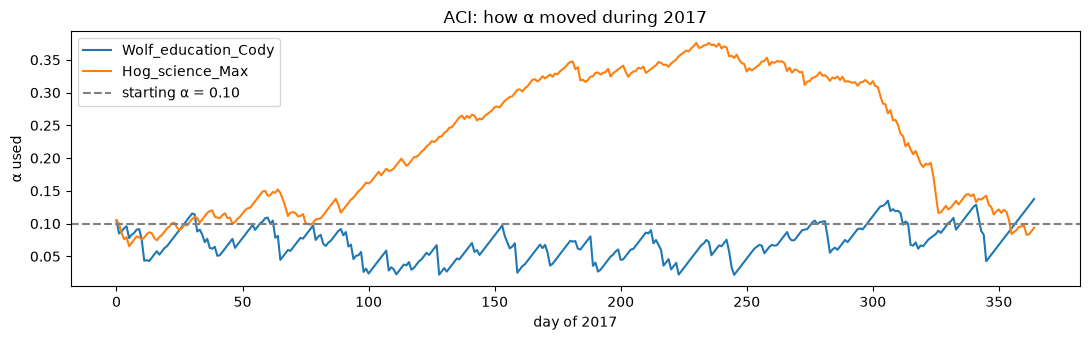

In [14]:
import matplotlib.pyplot as plt

worst = "Wolf_education_Cody"
calm = pd.Series({b: np.mean(p) for b, p in alpha_path.items()}).idxmax()
fig, ax = plt.subplots(figsize=(11, 3.5))
for b in [worst, calm]:
    if b in alpha_path:
        ax.plot(alpha_path[b], label=b)
ax.axhline(alpha, color="gray", ls="--", label="starting α = 0.10")
ax.set(xlabel="day of 2017", ylabel="α used", title="ACI: how α moved during 2017")
ax.legend()
fig.tight_layout()

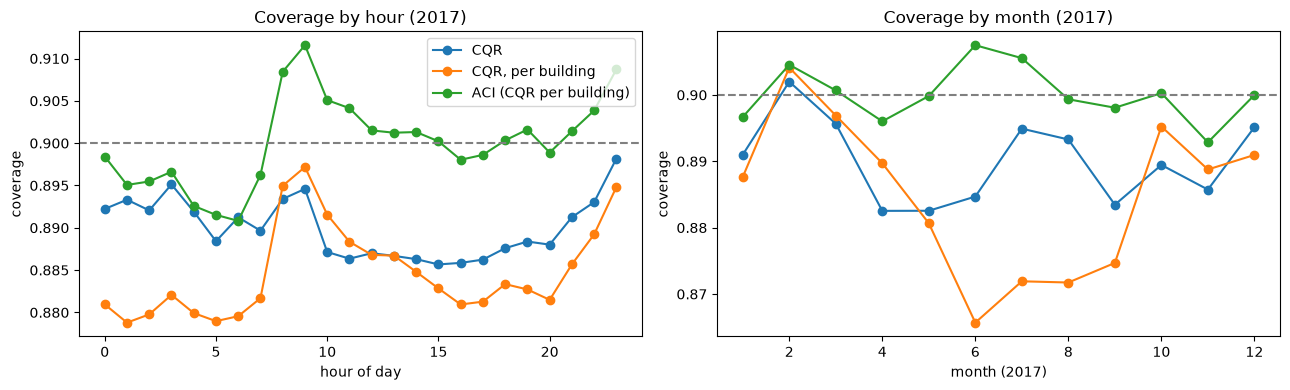

In [17]:
methods["CQR, per building"] = (lo_e, hi_e)
methods["ACI (CQR per building)"] = (lo_f * scale, hi_f * scale)
compare = ["CQR", "CQR, per building", "ACI (CQR per building)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in compare:
    lo, hi = methods[name]
    covered = pd.Series((y >= lo) & (y <= hi))
    axes[0].plot(covered.groupby(hours).mean(), marker="o", label=name)
    axes[1].plot(covered.groupby(months).mean(), marker="o", label=name)
for ax in axes:
    ax.axhline(0.9, color="gray", ls="--")
axes[0].set(xlabel="hour of day", ylabel="coverage", title="Coverage by hour (2017)")
axes[1].set(xlabel="month (2017)", ylabel="coverage", title="Coverage by month (2017)")
axes[0].legend()
fig.tight_layout()

level 0.5 done
level 0.8 done
level 0.9 done
level 0.95 done
 target  CQR per building coverage  CQR per building width  ACI coverage  ACI width
   0.50                      0.488                   0.157         0.499      0.163
   0.80                      0.784                   0.330         0.800      0.349
   0.90                      0.885                   0.475         0.900      0.508
   0.95                      0.935                   0.654         0.950      0.705


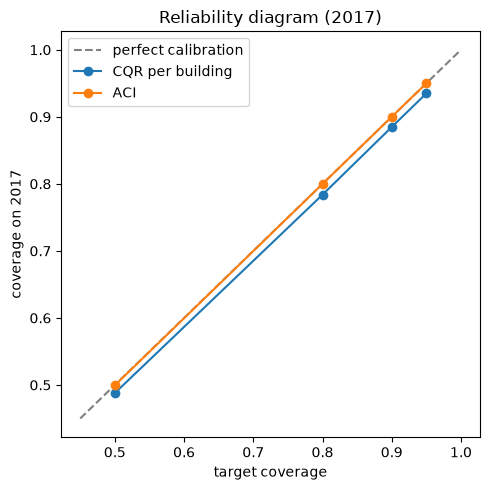

In [18]:
def conformal_q_a(r, a):
    n = len(r)
    lvl = min(1.0, max(0.0, np.ceil((n + 1) * (1 - a)) / n))
    return np.quantile(r, lvl, method="higher")

def run_level(level, gamma=0.05):
    a0 = 1 - level
    lo_m = HistGradientBoostingRegressor(loss="quantile", quantile=a0 / 2, random_state=0)
    hi_m = HistGradientBoostingRegressor(loss="quantile", quantile=1 - a0 / 2, random_state=0)
    lo_m.fit(fit[FEATS], fit["load_n"])
    hi_m.fit(fit[FEATS], fit["load_n"])
    s_all = np.maximum(lo_m.predict(cal[FEATS]) - y_cal, y_cal - hi_m.predict(cal[FEATS]))
    lo_t, hi_t = lo_m.predict(test[FEATS]), hi_m.predict(test[FEATS])

    # CQR per building
    q_b = pd.Series(s_all).groupby(cal_b).apply(lambda r: conformal_q_a(r.to_numpy(), a0))
    q_t = pd.Series(test_b).map(q_b).to_numpy()
    lo_pb, hi_pb = lo_t - q_t, hi_t + q_t

    # ACI on top, one update per day (same as Cell 8)
    lo_aci, hi_aci = np.full(len(test), np.nan), np.full(len(test), np.nan)
    for b in np.unique(test_b):
        s_b = s_all[cal_b == b]
        rows_b = np.flatnonzero(test_b == b)
        _, starts = np.unique(days[rows_b], return_index=True)
        bounds = list(starts) + [len(rows_b)]
        a = a0
        for k in range(len(starts)):
            idx = rows_b[bounds[k]:bounds[k + 1]]
            q = conformal_q_a(s_b, a)
            lo_aci[idx], hi_aci[idx] = lo_t[idx] - q, hi_t[idx] + q
            miss = 1 - ((y_n[idx] >= lo_aci[idx]) & (y_n[idx] <= hi_aci[idx])).mean()
            a = a + gamma * (a0 - miss)

    out = {"target": level}
    for name, lo, hi in [("CQR per building", lo_pb, hi_pb), ("ACI", lo_aci, hi_aci)]:
        out[name + " coverage"] = ((y_n >= lo) & (y_n <= hi)).mean()
        out[name + " width"] = (hi - lo).mean()
    print("level", level, "done", flush=True)
    return out

levels = [0.5, 0.8, 0.9, 0.95]
rel = pd.DataFrame([run_level(L) for L in levels])
print(rel.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0.45, 1], [0.45, 1], color="gray", ls="--", label="perfect calibration")
ax.plot(rel["target"], rel["CQR per building coverage"], marker="o", label="CQR per building")
ax.plot(rel["target"], rel["ACI coverage"], marker="o", label="ACI")
ax.set(xlabel="target coverage", ylabel="coverage on 2017", title="Reliability diagram (2017)")
ax.legend()
fig.tight_layout()

450059 fit rows, 281653 calibration rows
CQR per building, Nov–Dec: coverage 0.885, width 0.475, buildings < 80%: 4
CQR per building, seasonal: coverage 0.896, width 0.501, buildings < 80%: 0


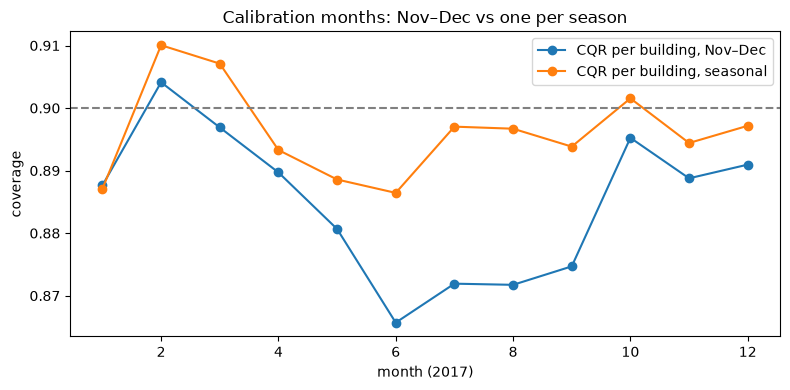

In [19]:
cal_months = [1, 4, 7, 10]
idx = data.index
in_2016 = idx.year == 2016
is_cal2 = in_2016 & np.isin(idx.month, cal_months)

gap = np.zeros(len(data), dtype=bool)
for m in cal_months:
    start = pd.Timestamp(2016, m, 1)
    end = start + pd.offsets.MonthEnd(1) + pd.Timedelta(hours=23)
    gap |= (idx >= start - pd.Timedelta(days=7)) & (idx < start)
    gap |= (idx > end) & (idx <= end + pd.Timedelta(days=7))

fit2 = data[in_2016 & ~is_cal2 & ~gap].dropna(subset=["load_n"])
cal2 = data[is_cal2].dropna(subset=["load_n"])
print(len(fit2), "fit rows,", len(cal2), "calibration rows")

qm = {q: HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0)
         .fit(fit2[FEATS], fit2["load_n"]) for q in [0.05, 0.95]}
y_cal2 = cal2["load_n"].to_numpy()
scores2 = np.maximum(qm[0.05].predict(cal2[FEATS]) - y_cal2, y_cal2 - qm[0.95].predict(cal2[FEATS]))
q_b2 = pd.Series(scores2).groupby(cal2["building"].to_numpy()).apply(lambda r: conformal_q(r.to_numpy()))
q_t2 = pd.Series(test_b).map(q_b2).to_numpy()
lo_s = (qm[0.05].predict(test[FEATS]) - q_t2) * scale
hi_s = (qm[0.95].predict(test[FEATS]) + q_t2) * scale

compare = {"CQR per building, Nov–Dec": (lo_e, hi_e),
           "CQR per building, seasonal": (lo_s, hi_s)}
fig, ax = plt.subplots(figsize=(8, 4))
for name, (lo, hi) in compare.items():
    covered = pd.Series((y >= lo) & (y <= hi))
    per_b = covered.groupby(buildings).mean()
    print(f"{name}: coverage {covered.mean():.3f}, width {np.mean((hi - lo) / scale):.3f}, "
          f"buildings < 80%: {(per_b < 0.8).sum()}")
    ax.plot(covered.groupby(months).mean(), marker="o", label=name)
ax.axhline(0.9, color="gray", ls="--")
ax.set(xlabel="month (2017)", ylabel="coverage", title="Calibration months: Nov–Dec vs one per season")
ax.legend()
fig.tight_layout()